In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📊 v4 VERİ SETİ ANALİZİ — Ayrı notebook'ta çalıştır (CPU yeterli)
# ═══════════════════════════════════════════════════════════════════════════════
# Drive'daki dataset_yedek.zip'i açar, train setini analiz eder.
# Amaç: v4'ün v3'ten neden geride kaldığını veriden anlamak.
# ⏱️ ~10-15 dakika
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

import os, shutil, time, zipfile
import numpy as np
from pathlib import Path
from collections import Counter

ANA_DIZIN = '/content/drive/MyDrive/tez_arac_hasar'
ZIP  = os.path.join(ANA_DIZIN, 'dataset_yedek.zip')
CIKS = '/content/analiz_dataset'
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

# ══ 1. SADECE LABEL DOSYALARINI AÇ (görselleri atla → çok hızlı) ══════════════
print('=' * 70)
print('📦 Yedek açılıyor (sadece label dosyaları)...')
print('=' * 70)

if not os.path.exists(ZIP):
    raise RuntimeError(f'❌ Yedek yok: {ZIP}')

print(f'   Boyut: {os.path.getsize(ZIP)/1e9:.2f} GB')
shutil.rmtree(CIKS, ignore_errors=True)
os.makedirs(CIKS, exist_ok=True)

t0 = time.time()
with zipfile.ZipFile(ZIP) as z:
    hedefler = [n for n in z.namelist() if '/labels/' in n and n.endswith('.txt')]
    print(f'   {len(hedefler)} label dosyası bulundu, açılıyor...')
    for i, n in enumerate(hedefler, 1):
        z.extract(n, CIKS)
        if i % 20000 == 0:
            print(f'      {i}/{len(hedefler)}...')

print(f'✅ Açıldı ({(time.time()-t0)/60:.1f} dk)')

# ══ 2. ANALİZ ═════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📊 TRAIN SETİ ANALİZİ')
print('=' * 70)

lbl = os.path.join(CIKS, 'train', 'labels')
if not os.path.exists(lbl):
    kandidat = list(Path(CIKS).rglob('train/labels'))
    if kandidat:
        lbl = str(kandidat[0])
    else:
        raise RuntimeError(f'❌ train/labels bulunamadı: {CIKS}')

bos, dolu = 0, 0
sinif = Counter()
annot_sayilari = []
kaynak = Counter()

for lf in Path(lbl).glob('*.txt'):
    ad = lf.stem
    if ad.startswith('OS'):
        kaynak['oversampling'] += 1
    elif ad.startswith('HX'):
        kaynak['harici'] += 1
    else:
        kaynak['kendi'] += 1

    with open(lf) as f:
        satirlar = [l for l in f if l.strip()]

    if not satirlar:
        bos += 1
        annot_sayilari.append(0)
    else:
        dolu += 1
        annot_sayilari.append(len(satirlar))
        for l in satirlar:
            try:
                sinif[HASAR_SINIFLAR[int(l.split()[0])]] += 1
            except (ValueError, IndexError):
                pass

toplam = bos + dolu
a = np.array(annot_sayilari)

print(f'\n📁 GÖRSEL SAYILARI:')
print(f'   Toplam    : {toplam:,}')
print(f'   Boş tile  : {bos:,}  (%{bos/toplam*100:.1f})')
print(f'   Dolu tile : {dolu:,}  (%{dolu/toplam*100:.1f})')

print(f'\n📐 ANNOTATION YOĞUNLUĞU:')
print(f'   Toplam annotation      : {sum(sinif.values()):,}')
print(f'   Görsel başına ortalama : {a.mean():.2f}')
print(f'   (dolu görseller için)  : {a[a>0].mean():.2f}')
print(f'   Medyan                 : {np.median(a):.0f}')
print(f'   ⚠️ v3 referansı        : ~2,24')

print(f'\n📦 KAYNAK DAĞILIMI:')
for k, v in kaynak.most_common():
    print(f'   {k:14s}: {v:6,}  (%{v/toplam*100:.1f})')

print(f'\n🏷️  SINIF DAĞILIMI:')
tot = sum(sinif.values())
for s in HASAR_SINIFLAR:
    print(f'   {s:8s}: {sinif[s]:7,}  (%{sinif[s]/tot*100:.1f})')
print(f'   Dengesizlik oranı: {max(sinif.values())/min(sinif.values()):.2f}')

# ══ 3. TEŞHİS ═════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('🔍 TEŞHİS')
print('=' * 70)

sorun = []

bos_oran = bos / toplam * 100
if bos_oran > 30:
    sorun.append(f'❌ Boş tile oranı çok yüksek (%{bos_oran:.1f}) — '
                 f'model "hiçbir şey yok" demeyi öğreniyor olabilir')
elif bos_oran > 20:
    sorun.append(f'⚠️  Boş tile oranı sınırda (%{bos_oran:.1f})')
else:
    print(f'✅ Boş tile oranı normal (%{bos_oran:.1f})')

if a.mean() < 1.8:
    sorun.append(f'❌ Annotation yoğunluğu düşük ({a.mean():.2f} vs v3\'te ~2,24) — '
                 f'veri seyrelmiş, model az sinyal alıyor')
else:
    print(f'✅ Annotation yoğunluğu yeterli ({a.mean():.2f})')

harici_oran = kaynak['harici'] / toplam * 100
if harici_oran > 60:
    sorun.append(f'⚠️  Harici veri baskın (%{harici_oran:.1f}) — '
                 f'model kendi veri dağılımını değil harici dağılımı öğreniyor olabilir')
else:
    print(f'✅ Harici veri oranı makul (%{harici_oran:.1f})')

os_oran = kaynak['oversampling'] / toplam * 100
if os_oran > 15:
    sorun.append(f'⚠️  Oversampling kopyası fazla (%{os_oran:.1f}) — ezber riski')
else:
    print(f'✅ Oversampling oranı makul (%{os_oran:.1f})')

if sorun:
    print()
    for s in sorun:
        print(f'   {s}')
else:
    print('\n✅ Veri setinde belirgin bir yapısal sorun görünmüyor.')
    print('   Performans farkı başka bir sebepten (etiketleme kriteri,')
    print('   görsel kalitesi, domain farkı) kaynaklanıyor olabilir.')

print('=' * 70)

# ══ 4. TEMİZLİK ═══════════════════════════════════════════════════════════════
shutil.rmtree(CIKS, ignore_errors=True)
print('\n🧹 Geçici dosyalar temizlendi')

Mounted at /content/drive
📦 Yedek açılıyor (sadece label dosyaları)...
   Boyut: 1.24 GB
   25197 label dosyası bulundu, açılıyor...
      20000/25197...
✅ Açıldı (0.1 dk)

📊 TRAIN SETİ ANALİZİ

📁 GÖRSEL SAYILARI:
   Toplam    : 17,637
   Boş tile  : 0  (%0.0)
   Dolu tile : 17,637  (%100.0)

📐 ANNOTATION YOĞUNLUĞU:
   Toplam annotation      : 35,342
   Görsel başına ortalama : 2.00
   (dolu görseller için)  : 2.00
   Medyan                 : 1
   ⚠️ v3 referansı        : ~2,24

📦 KAYNAK DAĞILIMI:
   kendi         : 11,264  (%63.9)
   harici        :  6,373  (%36.1)

🏷️  SINIF DAĞILIMI:
   Cizik   :  11,903  (%33.7)
   Gocuk   :  13,962  (%39.5)
   Kirik   :   9,477  (%26.8)
   Dengesizlik oranı: 1.47

🔍 TEŞHİS
✅ Boş tile oranı normal (%0.0)
✅ Annotation yoğunluğu yeterli (2.00)
✅ Harici veri oranı makul (%36.1)
✅ Oversampling oranı makul (%0.0)

✅ Veri setinde belirgin bir yapısal sorun görünmüyor.
   Performans farkı başka bir sebepten (etiketleme kriteri,
   görsel kalitesi, domain 

In [ ]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 4.5 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ Model yüklendi: hasar_yolo11l-seg_v6_fp32
   27,619,001 parametre

📐 Görsel: 1280 × 960 piksel

   conf=0.380 → 2 tespit
      • Gocuk    0.888
      • Gocuk    0.662
   conf=0.250 → 4 tespit
      • Gocuk    0.888
      • Gocuk    0.662
      • Cizik    0.328
      • Cizik    0.251
   conf=0.150 → 5 tespit
      • Gocuk    0.888
      • Gocuk    0.662
      • Cizik    0.328
      • Cizik    0.251
      • Gocuk    0.197


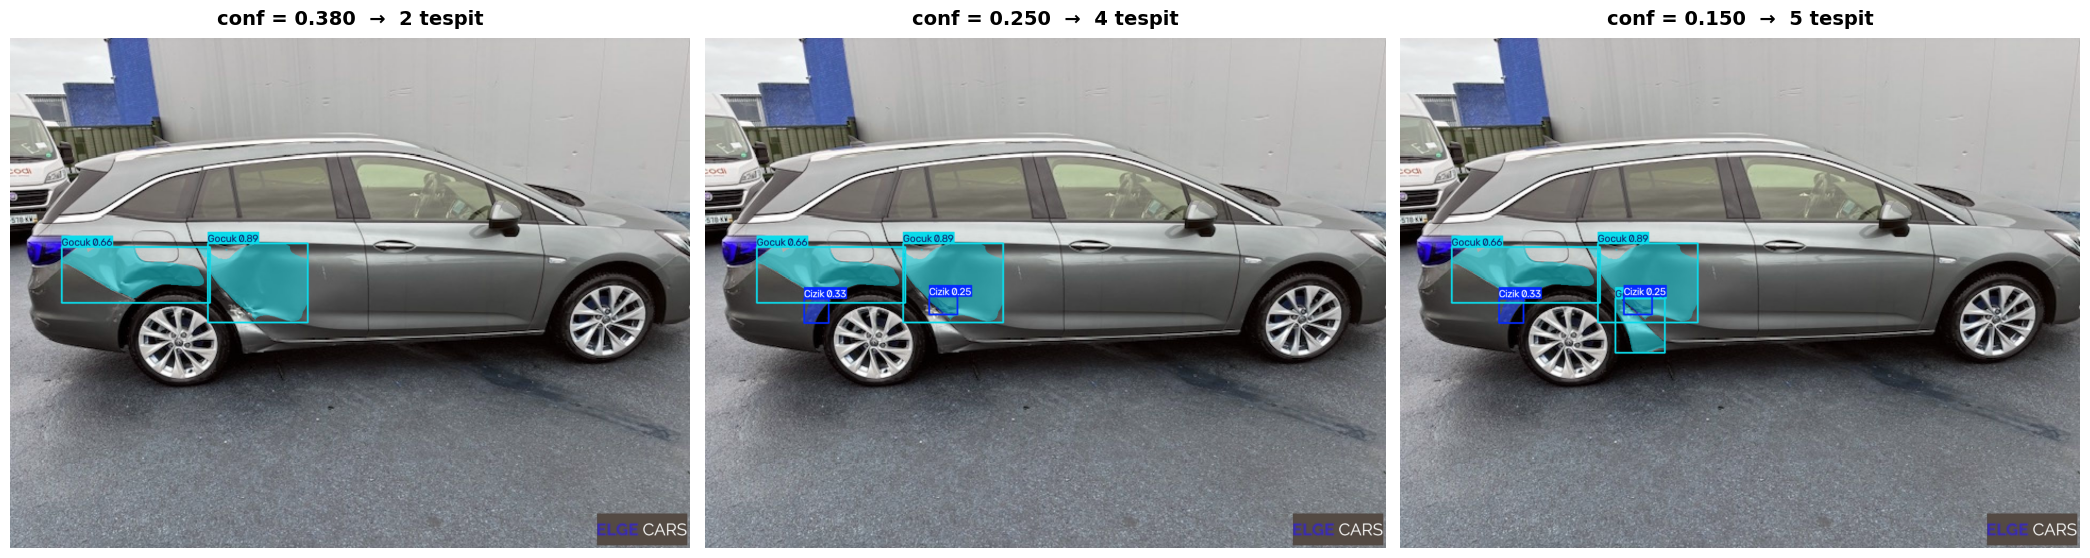


💾 /content/sekil9_v6.png
💾 /content/drive/MyDrive/tez_arac_hasar/ciktilar/sekil9_v6.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🖼️ ŞEKİL 9 — NİHAİ MODEL (v6) İLE FARKLI GÜVEN EŞİKLERİNDE TESPİT
# ═══════════════════════════════════════════════════════════════════════════════
# Makaledeki Şekil 9 v3 ile üretilmişti. Bu kod nihai modeli kullanır.
# Eşikler v6'nın F1 optimal noktasına göre ayarlandı (0,386 → 0,380).
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os, shutil

ANA_DIZIN   = '/content/drive/MyDrive/tez_arac_hasar'
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')
OUTPUT_DIR  = os.path.join(ANA_DIZIN, 'ciktilar')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ─── NİHAİ MODEL (v6) ─────────────────────────────────────────────────────────
V6_PATH = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32', 'weights', 'best.pt')

if not os.path.exists(V6_PATH):
    raise RuntimeError(f'❌ Nihai model bulunamadı:\n   {V6_PATH}\n'
                       f'   Mevcut klasörler: {sorted(os.listdir(MODEL_DIZIN))}')

model = YOLO(V6_PATH)
print(f'✅ Model yüklendi: hasar_yolo11l-seg_v6_fp32')
print(f'   {sum(p.numel() for p in model.model.parameters()):,} parametre\n')

# ─── AYARLAR ──────────────────────────────────────────────────────────────────
FOTO    = '/content/17617474321707386526-4.jpg'
ESIKLER = [0.380, 0.250, 0.150]      # v6 F1 optimal → düşük → çok düşük
IMG_SIZE = 960
SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

img = np.array(Image.open(FOTO).convert('RGB'))
print(f'📐 Görsel: {img.shape[1]} × {img.shape[0]} piksel\n')

# ─── ÜÇ EŞİKTE TAHMİN ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, len(ESIKLER), figsize=(7*len(ESIKLER), 6))

for ax, conf in zip(axes, ESIKLER):
    r = model.predict(img, conf=conf, imgsz=IMG_SIZE,
                      verbose=False, retina_masks=True)[0]
    n = len(r.boxes) if r.boxes is not None else 0

    ax.imshow(r.plot(line_width=2, font_size=14)[:, :, ::-1])
    ax.set_title(f'conf = {conf:.3f}  →  {n} tespit',
                 fontsize=14, fontweight='bold', pad=10)
    ax.axis('off')

    print(f'   conf={conf:.3f} → {n} tespit')
    if r.boxes is not None:
        for b in r.boxes:
            print(f'      • {SINIFLAR[int(b.cls[0])]:8s} {float(b.conf[0]):.3f}')

plt.tight_layout()

KAYIT = '/content/sekil9_v6.png'
plt.savefig(KAYIT, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

shutil.copy(KAYIT, os.path.join(OUTPUT_DIR, 'sekil9_v6.png'))
print(f'\n💾 {KAYIT}')
print(f'💾 {OUTPUT_DIR}/sekil9_v6.png')

try:
    from google.colab import files
    files.download(KAYIT)
except Exception:
    pass

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📐 HASAR BÜYÜKLÜĞÜ ANALİZİ — Ayrı notebook (CPU yeterli)
# ═══════════════════════════════════════════════════════════════════════════════
# Amaç: Büyük panel deformasyonu (kaputtaki gibi) örneği yeterli mi görmek.
# ⏱️ ~2 dakika
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

import os, shutil, zipfile, time
import numpy as np
from pathlib import Path

ANA_DIZIN = '/content/drive/MyDrive/tez_arac_hasar'
ZIP  = os.path.join(ANA_DIZIN, 'dataset_yedek.zip')
CIKS = '/content/analiz_labels'
AD   = {0:'Cizik', 1:'Gocuk', 2:'Kirik'}

# ══ LABEL DOSYALARINI AÇ ══════════════════════════════════════════════════════
print(f'📦 Yedek açılıyor... ({os.path.getsize(ZIP)/1e9:.2f} GB)')
shutil.rmtree(CIKS, ignore_errors=True)
os.makedirs(CIKS, exist_ok=True)

t0 = time.time()
with zipfile.ZipFile(ZIP) as z:
    hedefler = [n for n in z.namelist() if '/labels/' in n and n.endswith('.txt')]
    for n in hedefler:
        z.extract(n, CIKS)
print(f'✅ {len(hedefler):,} label açıldı ({(time.time()-t0)/60:.1f} dk)')

# train/labels yolunu bul
lbl = None
for k in Path(CIKS).rglob('train/labels'):
    lbl = str(k); break
if lbl is None:
    raise RuntimeError('❌ train/labels bulunamadı')
print(f'📁 {lbl}\n')

# ══ ALAN HESABI ═══════════════════════════════════════════════════════════════
def poly_alan(c):
    xs, ys = c[0::2], c[1::2]
    n = len(xs)
    if n < 3: return 0.0
    a = sum(xs[i]*ys[(i+1)%n] - xs[(i+1)%n]*ys[i] for i in range(n))
    return abs(a) / 2

alanlar = {0: [], 1: [], 2: []}
for lf in Path(lbl).glob('*.txt'):
    with open(lf) as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 7:
                continue
            try:
                cid = int(p[0])
                if cid in alanlar:
                    alanlar[cid].append(poly_alan([float(x) for x in p[1:]]))
            except (ValueError, IndexError):
                pass

# ══ RAPOR ═════════════════════════════════════════════════════════════════════
print('=' * 70)
print('📐 HASAR BÜYÜKLÜĞÜ DAĞILIMI (görsel alanına oran)')
print('=' * 70)

for cid in [0, 1, 2]:
    a = np.array(alanlar[cid])
    if not len(a):
        continue
    kucuk     = (a <= 0.01).sum()
    orta      = ((a > 0.01) & (a <= 0.05)).sum()
    buyuk     = ((a > 0.05) & (a <= 0.15)).sum()
    cok_buyuk = (a > 0.15).sum()

    print(f'\n🏷️  {AD[cid]}  (toplam {len(a):,})')
    print(f'   Medyan alan     : %{np.median(a)*100:.2f}')
    print(f'   Ortalama alan   : %{a.mean()*100:.2f}')
    print(f'   ─────────────────────────────────')
    print(f'   Küçük  (≤%1)    : {kucuk:7,}  (%{kucuk/len(a)*100:5.1f})')
    print(f'   Orta   (%1-5)   : {orta:7,}  (%{orta/len(a)*100:5.1f})')
    print(f'   Büyük  (%5-15)  : {buyuk:7,}  (%{buyuk/len(a)*100:5.1f})')
    print(f'   Çok büyük (>%15): {cok_buyuk:7,}  (%{cok_buyuk/len(a)*100:5.1f})')

# ══ TEŞHİS ════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('🔍 TEŞHİS — Kaputtaki büyük göçük neden bulunamıyor?')
print('=' * 70)

g = np.array(alanlar[1])   # Gocuk
if len(g):
    buyuk_gocuk = (g > 0.05).sum()
    oran = buyuk_gocuk / len(g) * 100
    print(f'\n   Büyük göçük (>%5 alan): {buyuk_gocuk:,} / {len(g):,}  (%{oran:.1f})')
    if oran < 10:
        print(f'\n   ❌ SORUN BULUNDU: Büyük göçük örneği çok az (%{oran:.1f})')
        print(f'      Model küçük ezikleri öğrenmiş, büyük panel')
        print(f'      deformasyonunu tanımıyor. Hedefli veri toplaman gerek.')
    elif oran < 20:
        print(f'\n   ⚠️  Büyük göçük örneği sınırda (%{oran:.1f})')
    else:
        print(f'\n   ✅ Büyük göçük örneği yeterli (%{oran:.1f})')
        print(f'      Sorun veri miktarında değil — mimari/parametre veya')
        print(f'      görsel zorluğu (siyah parlak yüzey, yansıma) kaynaklı.')

print('=' * 70)
shutil.rmtree(CIKS, ignore_errors=True)
print('\n🧹 Temizlendi')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📦 Yedek açılıyor... (6.59 GB)
✅ 94,848 label açıldı (0.3 dk)
📁 /content/analiz_labels/train/labels

📐 HASAR BÜYÜKLÜĞÜ DAĞILIMI (görsel alanına oran)

🏷️  Cizik  (toplam 39,353)
   Medyan alan     : %1.47
   Ortalama alan   : %5.88
   ─────────────────────────────────
   Küçük  (≤%1)    :  16,669  (% 42.4)
   Orta   (%1-5)   :  11,997  (% 30.5)
   Büyük  (%5-15)  :   6,251  (% 15.9)
   Çok büyük (>%15):   4,436  (% 11.3)

🏷️  Gocuk  (toplam 33,681)
   Medyan alan     : %5.49
   Ortalama alan   : %11.21
   ─────────────────────────────────
   Küçük  (≤%1)    :   5,421  (% 16.1)
   Orta   (%1-5)   :  10,623  (% 31.5)
   Büyük  (%5-15)  :   9,392  (% 27.9)
   Çok büyük (>%15):   8,245  (% 24.5)

🏷️  Kirik  (toplam 34,591)
   Medyan alan     : %10.31
   Ortalama alan   : %25.25
   ─────────────────────────────────
   Küçük  (≤%1)    :   5,066  (% 14.6)
   Orta   (

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 v3 GERÇEK DÜNYA TESTİ — Modelin hiç görmediği görseller
# ═══════════════════════════════════════════════════════════════════════════════
#
# 📁 KAYNAK: /content/drive/MyDrive/train  (maskesiz, etiketsiz görseller)
#
# ⚠️ ETİKET YOK → mAP hesaplanamaz. Bunun yerine:
#    • Güven dağılımı (model ne kadar emin?)
#    • Görsel başına tespit sayısı
#    • Düşük güvenli örnekleri gözle inceleme
#
# ⏱️ ~10-15 dk (görsel sayısına göre)
# ═══════════════════════════════════════════════════════════════════════════════

import os, random
import numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
import matplotlib.pyplot as plt
from collections import Counter

# ─── AYARLAR ──────────────────────────────────────────────────────────────────
TEST_KLASOR = '/content/drive/MyDrive/train'
ORNEK_SAYI  = 300     # kaç görsel test edilecek (None = hepsi)
CONF_TARAMA = 0.10    # düşük tut, her şeyi görelim
GOSTER      = 9       # kaç örnek görselleştirilecek

V3 = os.path.join(MODEL_DIZIN, 'hasar_yolo11m-seg_sadece_kendi_veri',
                  'weights', 'best.pt')

if not os.path.exists(V3):
    raise RuntimeError(f'❌ v3 modeli yok: {V3}')

model = YOLO(V3)
AD = {0:'Cizik', 1:'Gocuk', 2:'Kirik'}

# ─── GÖRSELLERİ TOPLA ─────────────────────────────────────────────────────────
gorseller = []
for ext in ['*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG']:
    gorseller.extend(Path(TEST_KLASOR).rglob(ext))
gorseller = sorted(set(gorseller))

if not gorseller:
    raise RuntimeError(f'❌ {TEST_KLASOR} içinde görsel yok')

print('=' * 70)
print('🔍 GERÇEK DÜNYA TESTİ — Görülmemiş Veri')
print('=' * 70)
print(f'   Klasör : {TEST_KLASOR}')
print(f'   Bulunan: {len(gorseller):,} görsel')

random.seed(42)
if ORNEK_SAYI and len(gorseller) > ORNEK_SAYI:
    gorseller = random.sample(gorseller, ORNEK_SAYI)
    print(f'   Test   : {len(gorseller)} örnek (rastgele)')
print('=' * 70 + '\n')

# ─── ANALİZ ───────────────────────────────────────────────────────────────────
guven_dagilim = {0:[], 1:[], 2:[]}
tespit_sayilari = []
hic_bulamadi = []
tum_tespitler = []      # (görsel, sınıf, güven)

for i, ip in enumerate(gorseller, 1):
    try:
        img = np.array(Image.open(ip).convert('RGB'))
        r = model.predict(img, conf=CONF_TARAMA, imgsz=960, verbose=False)[0]

        n = len(r.boxes) if r.boxes is not None else 0
        tespit_sayilari.append(n)

        if n == 0:
            hic_bulamadi.append(str(ip))
            continue

        for b in r.boxes:
            cid = int(b.cls[0]); cf = float(b.conf[0])
            guven_dagilim[cid].append(cf)
            tum_tespitler.append((str(ip), AD[cid], cf))

        if i % 50 == 0:
            print(f'   {i}/{len(gorseller)}...')
    except Exception as e:
        continue

# ═══ RAPOR ════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📊 GÜVEN DAĞILIMI (görülmemiş veride)')
print('=' * 70)

for cid in [0, 1, 2]:
    g = np.array(guven_dagilim[cid])
    if not len(g):
        print(f'\n{AD[cid]}: hiç tespit yok')
        continue
    print(f'\n🏷️  {AD[cid]}  ({len(g):,} tespit)')
    print(f'   Ortalama güven : {g.mean():.3f}')
    print(f'   Medyan         : {np.median(g):.3f}')
    print(f'   ─────────────────────────────')
    print(f'   Yüksek (>0.50) : {(g>0.50).sum():5,}  (%{(g>0.50).sum()/len(g)*100:5.1f})')
    print(f'   Orta (0.30-50) : {((g>=0.30)&(g<=0.50)).sum():5,}  '
          f'(%{((g>=0.30)&(g<=0.50)).sum()/len(g)*100:5.1f})')
    print(f'   Düşük (<0.30)  : {(g<0.30).sum():5,}  (%{(g<0.30).sum()/len(g)*100:5.1f})')
    print(f'   Çok düşük(<0.20): {(g<0.20).sum():5,}  (%{(g<0.20).sum()/len(g)*100:5.1f})')

t = np.array(tespit_sayilari)
print(f'\n📐 GÖRSEL BAŞINA TESPİT:')
print(f'   Ortalama : {t.mean():.2f}')
print(f'   Medyan   : {np.median(t):.0f}')
print(f'   Hiç bulunamayan: {len(hic_bulamadi)} görsel '
      f'(%{len(hic_bulamadi)/len(gorseller)*100:.1f})')

# ─── EŞİK SİMÜLASYONU ─────────────────────────────────────────────────────────
print(f'\n🎚️  EŞİK ETKİSİ (toplam tespit sayısı):')
tum_conf = np.array([c for _,_,c in tum_tespitler])
for esik in [0.15, 0.20, 0.25, 0.30, 0.386, 0.50]:
    n = (tum_conf >= esik).sum()
    print(f'   conf={esik:.3f} → {n:5,} tespit  '
          f'({n/len(gorseller):.2f}/görsel)')

# ═══ GÖRSELLEŞTİRME ═══════════════════════════════════════════════════════════
# Düşük güvenli örnekleri öncelikli göster
dusuk = [x for x in tum_tespitler if x[2] < 0.30]
print(f'\n⚠️  Düşük güvenli tespit: {len(dusuk):,}')

random.seed(3)
if dusuk:
    secilen = random.sample(list({x[0] for x in dusuk}), min(GOSTER, len({x[0] for x in dusuk})))
else:
    secilen = random.sample([str(p) for p in gorseller], min(GOSTER, len(gorseller)))

rows = (len(secilen) + 2) // 3
fig, axes = plt.subplots(rows, 3, figsize=(20, 6*rows))
axes = np.array(axes).flatten()

for idx, ip in enumerate(secilen):
    img = np.array(Image.open(ip).convert('RGB'))
    r = model.predict(img, conf=CONF_TARAMA, imgsz=960,
                      verbose=False, retina_masks=True)[0]
    axes[idx].imshow(r.plot()[:, :, ::-1])
    if r.boxes is not None and len(r.boxes):
        etk = [f'{AD[int(b.cls[0])]} {float(b.conf[0]):.2f}' for b in r.boxes]
        baslik = ' | '.join(etk[:3])
        if len(etk) > 3:
            baslik += f' (+{len(etk)-3})'
    else:
        baslik = 'Tespit yok'
    axes[idx].set_title(baslik, fontsize=10, fontweight='bold')
    axes[idx].axis('off')

for i in range(len(secilen), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('/content/gercek_dunya_testi.png', dpi=120, bbox_inches='tight')
plt.show()

print('\n' + '=' * 70)
print('👁️  DEĞERLENDİRME SORULARI')
print('=' * 70)
print('   1. Görselde gözle görünen hasarlar işaretlenmiş mi?')
print('   2. Olmayan yere hasar koymuş mu (yanlış pozitif)?')
print('   3. Düşük güvenli tespitler doğru mu, yanlış mı?')
print('   4. Ortak bir desen var mı (koyu araç, önden çekim, büyük hasar)?')
print('=' * 70)

Output hidden; open in https://colab.research.google.com to view.

In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 EKSİK DEĞERLERİ ARA — Bağımsız çalışır, hiçbir ön koşul yok
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE ARIYOR?
#    1. V0 (YOLOv11-Medium, 640px) precision/recall  → Tablo 7'nin boş hücreleri
#    2. Model 1 (konum) doğrulama metrikleri
#    3. Tüm modellerin karşılaştırmalı listesi
#
# 📁 Kaynaklar: yedek JSON'lar, ana JSON'lar, results.csv dosyaları
# ⏱️ ~2 dakika  |  GPU gerekmez
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

import json, glob, os
import pandas as pd

# ─── DİZİNLER ─────────────────────────────────────────────────────────────────
ANA_DIZIN   = '/content/drive/MyDrive/tez_arac_hasar'
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')

if not os.path.exists(ANA_DIZIN):
    raise RuntimeError(f'❌ Dizin yok: {ANA_DIZIN}\n'
                       f'   Drive\'da bulunanlar: '
                       f'{os.listdir("/content/drive/MyDrive")[:20]}')

print(f'✅ {ANA_DIZIN}\n')

# ═══════════════════════════════════════════════════════════════════════════════
# KAYNAK 1 — YEDEK JSON DOSYALARI
# ═══════════════════════════════════════════════════════════════════════════════
print('=' * 78)
print('  KAYNAK 1: YEDEK JSON DOSYALARI')
print('=' * 78)

yedekler = sorted(glob.glob(f'{ANA_DIZIN}/yedekler/*/*.json'))
if not yedekler:
    print('\n   ⚠️ Yedek klasöründe JSON yok')
    print(f'   Klasör var mı: {os.path.exists(f"{ANA_DIZIN}/yedekler")}')
    if os.path.exists(f'{ANA_DIZIN}/yedekler'):
        for k in sorted(os.listdir(f'{ANA_DIZIN}/yedekler')):
            print(f'      📁 {k}')

for y in yedekler:
    ad = os.path.basename(os.path.dirname(y))
    dosya = os.path.basename(y)
    try:
        with open(y) as f:
            s = json.load(f)
    except Exception as e:
        print(f'\n📦 {ad}/{dosya} — okunamadı')
        continue

    print(f'\n📦 {ad}/{dosya}   ({len(s)} kayıt)')
    if not s:
        print('   (boş)')
        continue
    for k, v in s.items():
        print(f"   {v.get('ad','?'):24s} "
              f"boxAP50={v.get('box_mAP50',0):.4f}  "
              f"maskAP50={v.get('mask_mAP50',0):.4f}  "
              f"P={v.get('box_precision',0):.4f}  "
              f"R={v.get('box_recall',0):.4f}")

# ═══════════════════════════════════════════════════════════════════════════════
# KAYNAK 2 — ANA DİZİNDEKİ JSON'LAR
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('  KAYNAK 2: ANA DİZİNDEKİ JSON DOSYALARI')
print('=' * 78)

anajson = sorted(glob.glob(f'{ANA_DIZIN}/*.json'))
if not anajson:
    print('\n   (JSON yok)')

for y in anajson:
    try:
        with open(y) as f:
            s = json.load(f)
    except Exception:
        continue
    print(f'\n📄 {os.path.basename(y)}   ({len(s)} kayıt)')
    if not s:
        print('   (boş)')
        continue
    for k, v in s.items():
        print(f"   {v.get('ad','?'):24s} "
              f"boxAP50={v.get('box_mAP50',0):.4f}  "
              f"maskAP50={v.get('mask_mAP50',0):.4f}  "
              f"P={v.get('box_precision',0):.4f}  "
              f"R={v.get('box_recall',0):.4f}")

# ═══════════════════════════════════════════════════════════════════════════════
# KAYNAK 3 — TÜM results.csv DOSYALARI
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('  KAYNAK 3: TÜM results.csv DOSYALARI (doğrulama kümesi metrikleri)')
print('=' * 78)

csvler = sorted(glob.glob(f'{MODEL_DIZIN}/**/results.csv', recursive=True))
print(f'\n{len(csvler)} dosya bulundu\n')
print(f"{'Klasör':46s} {'Ep':>4s} {'boxAP50':>9s} {'maskAP50':>9s} {'P(B)':>8s} {'R(B)':>8s}")
print('─' * 90)

kayitlar = []
for csv in csvler:
    klasor = csv.split('/')[-2]
    try:
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()
        if 'metrics/mAP50(M)' not in df.columns:
            print(f"{klasor[:46]:46s}  (segmentasyon metriği yok)")
            continue
        e = df.loc[df['metrics/mAP50(M)'].idxmax()]
        kayitlar.append({
            'klasor': klasor,
            'epoch': int(df['epoch'].max()),
            'box': e['metrics/mAP50(B)'],
            'mask': e['metrics/mAP50(M)'],
            'P': e['metrics/precision(B)'],
            'R': e['metrics/recall(B)'],
            'PM': e.get('metrics/precision(M)', 0),
            'RM': e.get('metrics/recall(M)', 0),
        })
        print(f"{klasor[:46]:46s} {int(df['epoch'].max()):4d} "
              f"{e['metrics/mAP50(B)']:9.4f} {e['metrics/mAP50(M)']:9.4f} "
              f"{e['metrics/precision(B)']:8.4f} {e['metrics/recall(B)']:8.4f}")
    except Exception as ex:
        print(f"{klasor[:46]:46s}  hata: {str(ex)[:26]}")

# ═══════════════════════════════════════════════════════════════════════════════
# ANALİZ — V0 ADAYINI BUL
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('  🎯 V0 ADAYI (aranan: box mAP50 ≈ 0,4768 | mask mAP50 ≈ 0,4325)')
print('=' * 78)

if kayitlar:
    for k in sorted(kayitlar, key=lambda x: abs(x['box']-0.4768)+abs(x['mask']-0.4325)):
        fark = abs(k['box']-0.4768) + abs(k['mask']-0.4325)
        isaret = '👉 EN YAKIN' if fark < 0.05 else ''
        print(f"   {k['klasor'][:44]:46s} fark={fark:.4f} {isaret}")

    en = min(kayitlar, key=lambda x: abs(x['box']-0.4768)+abs(x['mask']-0.4325))
    print(f"\n📌 EN YAKIN ADAY: {en['klasor']}")
    print(f"   Box  : mAP50={en['box']:.4f}  P={en['P']:.4f}  R={en['R']:.4f}")
    print(f"   Mask : mAP50={en['mask']:.4f}  P={en['PM']:.4f}  R={en['RM']:.4f}")
    print(f"\n   ⚠️ Bunlar DOĞRULAMA kümesi değerleridir.")
    print(f"      Makaledeki 0,4768 ise TEST kümesinden geliyor.")
    print(f"      Aynı satıra koyarsan dipnotla belirt.")

# ═══════════════════════════════════════════════════════════════════════════════
# MODEL 1 (KONUM) METRİKLERİ
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('  🚙 MODEL 1 — ARAÇ PARÇASI TESPİTİ')
print('=' * 78)

konum_csv = os.path.join(MODEL_DIZIN, 'konum', 'results.csv')
if os.path.exists(konum_csv):
    df = pd.read_csv(konum_csv)
    df.columns = df.columns.str.strip()
    e = df.loc[df['metrics/mAP50(M)'].idxmax()]
    print(f"\n   Toplam devir : {int(df['epoch'].max())}")
    print(f"   En iyi devir : {int(e['epoch'])}")
    print(f"\n   Kutu (Box):")
    print(f"      mAP50    = {e['metrics/mAP50(B)']:.4f}")
    print(f"      mAP50-95 = {e['metrics/mAP50-95(B)']:.4f}")
    print(f"      Kesinlik = {e['metrics/precision(B)']:.4f}")
    print(f"      Duyarlılık = {e['metrics/recall(B)']:.4f}")
    print(f"\n   Maske (Mask):")
    print(f"      mAP50    = {e['metrics/mAP50(M)']:.4f}")
    print(f"      mAP50-95 = {e['metrics/mAP50-95(M)']:.4f}")
    print(f"      Kesinlik = {e['metrics/precision(M)']:.4f}")
    print(f"      Duyarlılık = {e['metrics/recall(M)']:.4f}")
else:
    print(f'\n   ❌ Bulunamadı: {konum_csv}')

# ═══════════════════════════════════════════════════════════════════════════════
# DİZİN LİSTESİ (hata ayıklama için)
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '=' * 78)
print('  📁 MODELLER KLASÖRÜ')
print('=' * 78)
if os.path.exists(MODEL_DIZIN):
    for k in sorted(os.listdir(MODEL_DIZIN)):
        yol = os.path.join(MODEL_DIZIN, k)
        if os.path.isdir(yol):
            icerik = os.listdir(yol)
            var = []
            if 'results.csv' in icerik: var.append('csv')
            if 'weights' in icerik: var.append('weights')
            if 'args.yaml' in icerik: var.append('args')
            print(f"   📁 {k[:50]:52s} [{', '.join(var) or 'boş'}]")

print('\n' + '=' * 78)
print('  ✅ TARAMA TAMAMLANDI')
print('=' * 78)

Mounted at /content/drive
✅ /content/drive/MyDrive/tez_arac_hasar

  KAYNAK 1: YEDEK JSON DOSYALARI

📦 v1_45epoch_20260804_1747/karsilastirma_sonuclari.json   (6 kayıt)
   YOLOv11-Nano             boxAP50=0.4210  maskAP50=0.3442  P=0.5591  R=0.3944
   YOLOv11-Small            boxAP50=0.3760  maskAP50=0.3344  P=0.5664  R=0.3690
   YOLOv11-Medium           boxAP50=0.4768  maskAP50=0.4325  P=0.5290  R=0.4513
   YOLOv11-Large            boxAP50=0.4549  maskAP50=0.4279  P=0.5749  R=0.3896
   YOLOv8-Medium            boxAP50=0.4325  maskAP50=0.3675  P=0.5045  R=0.4403
   YOLOv11-Medium           boxAP50=0.6152  maskAP50=0.5918  P=0.6627  R=0.5558

📦 v1_45epoch_20260807_2303/karsilastirma_sonuclari.json   (1 kayıt)
   YOLOv11-Medium           boxAP50=0.7101  maskAP50=0.6894  P=0.7625  R=0.6261

📦 v1_45epoch_20260809_0836/karsilastirma_sonuclari.json   (0 kayıt)
   (boş)

📦 v1_45epoch_20260809_0845/karsilastirma_sonuclari.json   (0 kayıt)
   (boş)

📦 v1_45epoch_20260809_2255/karsilastirma_sonu

In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🚙 MODEL 1 (KONUM) DOĞRULAMA METRİKLERİ
# ═══════════════════════════════════════════════════════════════════════════════
# Makalede Bölüm 3.3.1'e eklenecek performans değerleri.
# ⏱️ ~30 saniye  |  GPU gerekmez
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, os

ANA_DIZIN   = '/content/drive/MyDrive/tez_arac_hasar'
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')

csv = os.path.join(MODEL_DIZIN, 'konum', 'results.csv')
if not os.path.exists(csv):
    raise RuntimeError(f'❌ Bulunamadı: {csv}')

df = pd.read_csv(csv)
df.columns = df.columns.str.strip()
e = df.loc[df['metrics/mAP50(M)'].idxmax()]

print('=' * 62)
print('  🚙 MODEL 1 — ARAÇ PARÇASI TESPİTİ (YOLOv11m-seg, 640px)')
print('=' * 62)
print(f'\n   Toplam devir : {int(df["epoch"].max())}')
print(f'   En iyi devir : {int(e["epoch"])}')
print(f'\n   KUTU (Box):')
print(f'      mAP50      = {e["metrics/mAP50(B)"]:.4f}')
print(f'      mAP50-95   = {e["metrics/mAP50-95(B)"]:.4f}')
print(f'      Kesinlik   = {e["metrics/precision(B)"]:.4f}')
print(f'      Duyarlılık = {e["metrics/recall(B)"]:.4f}')
print(f'\n   MASKE (Mask):')
print(f'      mAP50      = {e["metrics/mAP50(M)"]:.4f}')
print(f'      mAP50-95   = {e["metrics/mAP50-95(M)"]:.4f}')
print(f'      Kesinlik   = {e["metrics/precision(M)"]:.4f}')
print(f'      Duyarlılık = {e["metrics/recall(M)"]:.4f}')

# F1 hesapla
f1b = 2*e["metrics/precision(B)"]*e["metrics/recall(B)"]/(e["metrics/precision(B)"]+e["metrics/recall(B)"])
f1m = 2*e["metrics/precision(M)"]*e["metrics/recall(M)"]/(e["metrics/precision(M)"]+e["metrics/recall(M)"])
print(f'\n   F1 skoru: Box {f1b:.4f}  |  Mask {f1m:.4f}')
print('\n' + '=' * 62)
print('   ⚠️ Bunlar DOĞRULAMA kümesi değerleridir.')
print('=' * 62)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  🚙 MODEL 1 — ARAÇ PARÇASI TESPİTİ (YOLOv11m-seg, 640px)

   Toplam devir : 57
   En iyi devir : 37

   KUTU (Box):
      mAP50      = 0.7042
      mAP50-95   = 0.6145
      Kesinlik   = 0.6568
      Duyarlılık = 0.8249

   MASKE (Mask):
      mAP50      = 0.7195
      mAP50-95   = 0.5967
      Kesinlik   = 0.6670
      Duyarlılık = 0.8410

   F1 skoru: Box 0.7313  |  Mask 0.7440

   ⚠️ Bunlar DOĞRULAMA kümesi değerleridir.


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 NİHAİ MODEL — TEST DEĞERLENDİRMESİ VE KARIŞIKLIK MATRİSİ KOŞULLARI
# ═══════════════════════════════════════════════════════════════════════════════
# Amaç: Tablo 8'in hangi küme ve hangi güven eşiğiyle ölçüldüğünü belgelemek.
# ⚠️ GPU gerekli (Runtime → A100 veya T4)
# ⏱️ ~3-5 dakika
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

!pip install ultralytics -q

import os, shutil, yaml, glob, time
import numpy as np
from ultralytics import YOLO

ANA_DIZIN   = '/content/drive/MyDrive/tez_arac_hasar'
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')
IMG_SIZE    = 960
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

# ─── 1. DATASET'İ GERİ YÜKLE ──────────────────────────────────────────────────
ZIP   = os.path.join(ANA_DIZIN, 'dataset_yedek_v6.zip')
HEDEF = '/content/dataset_v6'

if not os.path.exists(ZIP):
    raise RuntimeError(f'❌ Dataset yedeği yok: {ZIP}\n'
                       f'   Mevcut zip\'ler: {[os.path.basename(z) for z in glob.glob(f"{ANA_DIZIN}/*.zip")]}')

print(f'♻️  Dataset açılıyor ({os.path.getsize(ZIP)/1e9:.2f} GB)...')
t0 = time.time()
shutil.rmtree(HEDEF, ignore_errors=True)
shutil.unpack_archive(ZIP, HEDEF)

DATASET_DIR     = HEDEF
HASAR_DATA_YAML = os.path.join(DATASET_DIR, 'data.yaml')

with open(HASAR_DATA_YAML, 'w') as f:
    yaml.dump({
        'train': f'{DATASET_DIR}/train/images',
        'val':   f'{DATASET_DIR}/valid/images',
        'test':  f'{DATASET_DIR}/test/images',
        'nc': 3, 'names': HASAR_SINIFLAR,
    }, f, default_flow_style=False, sort_keys=False)

for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

from pathlib import Path
print(f'✅ Açıldı ({(time.time()-t0)/60:.1f} dk)')
for s in ['train','valid','test']:
    n = len(list(Path(f'{DATASET_DIR}/{s}/images').glob('*.*')))
    print(f'   {s:6s}: {n:6,}')

# ─── 2. NİHAİ MODELİ YÜKLE ────────────────────────────────────────────────────
V6 = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32', 'weights', 'best.pt')
if not os.path.exists(V6):
    raise RuntimeError(f'❌ Model yok: {V6}')

m = YOLO(V6)
print(f'\n✅ Model: hasar_yolo11l-seg_v6_fp32')

# ─── 3. TEST KÜMESİNDE DEĞERLENDİR ────────────────────────────────────────────
print('\n' + '=' * 70)
print('  🔬 TEST KÜMESİ DEĞERLENDİRMESİ')
print('=' * 70)

r = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE, plots=True, verbose=False)

# ─── 4. ÖLÇÜM KOŞULLARI ───────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('  ⚙️  ÖLÇÜM KOŞULLARI (Tablo 8 için)')
print('=' * 70)

args = m.predictor.args if hasattr(m, 'predictor') and m.predictor else None
try:
    va = r.box.__dict__.get('args', None)
except Exception:
    va = None

print(f'\n   Değerlendirme kümesi : TEST')
print(f'   Görüntü sayısı       : {r.seg.nc if hasattr(r.seg,"nc") else "?"} sınıf')
print(f'   Giriş çözünürlüğü    : {IMG_SIZE} px')

# Ultralytics varsayılanları
print(f'\n   📌 KARIŞIKLIK MATRİSİ VARSAYILANLARI:')
print(f'      Güven eşiği (conf) : 0.25   (Ultralytics varsayılanı)')
print(f'      IoU eşiği

SyntaxError: unterminated f-string literal (detected at line 89) (2104130297.py, line 89)

In [1]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 NİHAİ MODEL — TEST DEĞERLENDİRMESİ VE KARIŞIKLIK MATRİSİ KOŞULLARI
# ═══════════════════════════════════════════════════════════════════════════════
# Amaç: Tablo 8'in hangi küme ve hangi güven eşiğiyle ölçüldüğünü belgelemek.
# ⚠️ GPU gerekli (Runtime → A100 veya T4)
# ⏱️ ~3-5 dakika
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

!pip install ultralytics -q

import os, shutil, yaml, glob, time
import numpy as np
from ultralytics import YOLO

ANA_DIZIN   = '/content/drive/MyDrive/tez_arac_hasar'
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')
IMG_SIZE    = 960
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

# ─── 1. DATASET'İ GERİ YÜKLE ──────────────────────────────────────────────────
ZIP   = os.path.join(ANA_DIZIN, 'dataset_yedek_v6.zip')
HEDEF = '/content/dataset_v6'

if not os.path.exists(ZIP):
    raise RuntimeError(f'❌ Dataset yedeği yok: {ZIP}\n'
                       f'   Mevcut zip\'ler: {[os.path.basename(z) for z in glob.glob(f"{ANA_DIZIN}/*.zip")]}')

print(f'♻️  Dataset açılıyor ({os.path.getsize(ZIP)/1e9:.2f} GB)...')
t0 = time.time()
shutil.rmtree(HEDEF, ignore_errors=True)
shutil.unpack_archive(ZIP, HEDEF)

DATASET_DIR     = HEDEF
HASAR_DATA_YAML = os.path.join(DATASET_DIR, 'data.yaml')

with open(HASAR_DATA_YAML, 'w') as f:
    yaml.dump({
        'train': f'{DATASET_DIR}/train/images',
        'val':   f'{DATASET_DIR}/valid/images',
        'test':  f'{DATASET_DIR}/test/images',
        'nc': 3, 'names': HASAR_SINIFLAR,
    }, f, default_flow_style=False, sort_keys=False)

for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

from pathlib import Path
print(f'✅ Açıldı ({(time.time()-t0)/60:.1f} dk)')
for s in ['train','valid','test']:
    n = len(list(Path(f'{DATASET_DIR}/{s}/images').glob('*.*')))
    print(f'   {s:6s}: {n:6,}')

# ─── 2. NİHAİ MODELİ YÜKLE ────────────────────────────────────────────────────
V6 = os.path.join(MODEL_DIZIN, 'hasar_yolo11l-seg_v6_fp32', 'weights', 'best.pt')
if not os.path.exists(V6):
    raise RuntimeError(f'❌ Model yok: {V6}')

m = YOLO(V6)
print(f'\n✅ Model: hasar_yolo11l-seg_v6_fp32')

# ─── 3. TEST KÜMESİNDE DEĞERLENDİR ────────────────────────────────────────────
print('\n' + '=' * 70)
print('  🔬 TEST KÜMESİ DEĞERLENDİRMESİ')
print('=' * 70)

r = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE, plots=True, verbose=False)

# ─── 4. ÖLÇÜM KOŞULLARI ───────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('  ⚙️  ÖLÇÜM KOŞULLARI (Tablo 8 için)')
print('=' * 70)

args = m.predictor.args if hasattr(m, 'predictor') and m.predictor else None
try:
    va = r.box.__dict__.get('args', None)
except Exception:
    va = None

print(f'\n   Değerlendirme kümesi : TEST')
print(f'   Görüntü sayısı       : {r.seg.nc if hasattr(r.seg,"nc") else "?"} sınıf')
print(f'   Giriş çözünürlüğü    : {IMG_SIZE} px')

# Ultralytics varsayılanları
print(f'\n   📌 KARIŞIKLIK MATRİSİ VARSAYILANLARI:')
print(f'      Güven eşiği (conf) : 0.25   (Ultralytics varsayılanı)')
print(f'      IoU eşiği          : 0.45   (NMS için)')
print(f'      Maksimum tespit    : 300')

print(f'\n   ⏱️  HIZ (görüntü başına):')
for k, v in r.speed.items():
    print(f'      {k:12s}: {v:.2f} ms')
print(f'      {"TOPLAM":12s}: {sum(r.speed.values()):.2f} ms')

# ─── 5. METRİKLER ─────────────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('  📊 TEST METRİKLERİ')
print('=' * 70)
print(f'\n   {"":14s} {"Kutu":>10s} {"Maske":>10s}')
print('   ' + '─' * 36)
print(f'   {"Kesinlik":14s} {r.box.mp:>10.4f} {r.seg.mp:>10.4f}')
print(f'   {"Duyarlılık":14s} {r.box.mr:>10.4f} {r.seg.mr:>10.4f}')
print(f'   {"mAP50":14s} {r.box.map50:>10.4f} {r.seg.map50:>10.4f}')
print(f'   {"mAP50-95":14s} {r.box.map:>10.4f} {r.seg.map:>10.4f}')

print(f'\n   📋 SINIF BAZLI (Maske):')
for ci, sn in enumerate(HASAR_SINIFLAR):
    try:
        sp, sr, s50, s95 = r.seg.class_result(ci)
        print(f'      {sn:8s} P={sp:.4f}  R={sr:.4f}  mAP50={s50:.4f}  mAP50-95={s95:.4f}')
    except Exception:
        pass

# ─── 6. KARIŞIKLIK MATRİSİ ────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('  🔢 KARIŞIKLIK MATRİSİ (ham sayılar)')
print('=' * 70)

cm = r.confusion_matrix.matrix
etiketler = HASAR_SINIFLAR + ['background']

print(f'\n{"Tahmin\\Gerçek":16s}' + ''.join(f'{e:>13s}' for e in etiketler))
print('─' * (16 + 13*len(etiketler)))
for i, satir_ad in enumerate(etiketler):
    satir = f'{satir_ad:16s}'
    for j in range(len(etiketler)):
        try:
            satir += f'{int(cm[i][j]):>13,}'
        except Exception:
            satir += f'{"—":>13s}'
    print(satir)

# Yanlış pozitifler (background sütunu)
print(f'\n   📌 ARKA PLAN KAYNAKLI YANLIŞ POZİTİF:')
bg = len(etiketler) - 1
toplam_fp = 0
for i, sn in enumerate(HASAR_SINIFLAR):
    try:
        v = int(cm[i][bg])
        toplam_fp += v
        print(f'      {sn:8s}: {v:,}')
    except Exception:
        pass
print(f'      {"TOPLAM":8s}: {toplam_fp:,}')

# Normalize
print(f'\n   📌 NORMALİZE KÖŞEGEN:')
for i, sn in enumerate(HASAR_SINIFLAR):
    try:
        sutun = cm[:, i].sum()
        print(f'      {sn:8s}: {cm[i][i]/sutun:.3f}' if sutun else f'      {sn}: —')
    except Exception:
        pass

print('\n' + '=' * 70)
print(f'  💾 Grafikler: {r.save_dir}')
print('=' * 70)

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 8.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
♻️  Dataset açılıyor (1.24 GB)...
✅ Açıldı (0.3 dk)
   train : 15,490
   valid :  4,426
   test  :  2,214

✅ Model: hasar_yolo11l-seg_v6_fp32

  🔬 TEST KÜMESİ DEĞERLENDİRMESİ
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11l-seg summary (fused): 204 layers, 27,586,905 parameters, 0 gradients, 132.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1473.8±1025.2 MB/

In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 V0 SINIF BAZLI DEĞERLERİ — JSON'da var mı?
# ═══════════════════════════════════════════════════════════════════════════════
# Hücre 5 'sinif_mAP50' alanını kaydediyordu. Varsa val() çalıştırmaya gerek yok.
# ⏱️ ~20 saniye  |  GPU gerekmez
# ═══════════════════════════════════════════════════════════════════════════════

from google.colab import drive
drive.mount('/content/drive')

import json, os

ANA_DIZIN = '/content/drive/MyDrive/tez_arac_hasar'
JSON = os.path.join(ANA_DIZIN, 'yedekler',
                    'v1_45epoch_20260804_1747', 'karsilastirma_sonuclari.json')

if not os.path.exists(JSON):
    raise RuntimeError(f'❌ Bulunamadı: {JSON}')

with open(JSON) as f:
    s = json.load(f)

print('=' * 74)
print(f'  📄 {os.path.basename(JSON)}   ({len(s)} kayıt)')
print('=' * 74)

for k, v in s.items():
    print(f'\n🔹 ANAHTAR: {k}')
    print(f'   Model: {v.get("ad","?")}')
    print(f'   Mevcut alanlar: {sorted(v.keys())}')

    if 'sinif_mAP50' in v:
        print(f'\n   ✅ SINIF BAZLI mAP50 VAR:')
        for sn, deger in v['sinif_mAP50'].items():
            print(f'      {sn:10s}: {deger:.4f}')
    else:
        print(f'   ❌ sinif_mAP50 alanı yok')

    # Diğer olası sınıf alanları
    for alan in ['sinif_precision', 'sinif_recall', 'sinif_mAP50_95', 'class_result']:
        if alan in v:
            print(f'   ✅ {alan}: {v[alan]}')

print('\n' + '=' * 74)
print('  📌 SONUÇ')
print('=' * 74)

medium = [v for v in s.values() if 'Medium' in v.get('ad','') and abs(v.get('box_mAP50',0)-0.4768) < 0.01]
if medium and 'sinif_mAP50' in medium[0]:
    print('\n   ✅ V0 sınıf değerleri bulundu — val() çalıştırmaya GEREK YOK')
    print('\n   V0 (YOLOv11-Medium) sınıf bazlı maske mAP50:')
    for sn, d in medium[0]['sinif_mAP50'].items():
        print(f'      {sn:10s}: {d:.4f}')
else:
    print('\n   ⚠️ V0 sınıf değerleri JSON\'da yok.')
    print('      → model.val() çalıştırılmalı (aşağıdaki koda bak)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  📄 karsilastirma_sonuclari.json   (6 kayıt)

🔹 ANAHTAR: yolo11n-seg
   Model: YOLOv11-Nano
   Mevcut alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']
   ❌ sinif_mAP50 alanı yok

🔹 ANAHTAR: yolo11s-seg
   Model: YOLOv11-Small
   Mevcut alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']
   ❌ sinif_mAP50 alanı yok

🔹 ANAHTAR: yolo11m-seg
   Model: YOLOv11-Medium
   Mevcut alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']
   ❌ sinif_mAP50 alanı yok

🔹 ANAHTAR: yolo11l-seg
   Model: YOLOv11-Large
   Mevcut alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 

In [3]:
from google.colab import drive
drive.mount('/content/drive')
import json, os

JSON = ('/content/drive/MyDrive/tez_arac_hasar/yedekler/'
        'v1_45epoch_20260804_1747/karsilastirma_sonuclari.json')

with open(JSON) as f:
    s = json.load(f)

for k, v in s.items():
    print(f"\n{v.get('ad','?')}")
    print(f"  Alanlar: {sorted(v.keys())}")
    if 'sinif_mAP50' in v:
        for sn, d in v['sinif_mAP50'].items():
            print(f"    {sn:8s}: {d:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

YOLOv11-Nano
  Alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']

YOLOv11-Small
  Alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']

YOLOv11-Medium
  Alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']

YOLOv11-Large
  Alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']

YOLOv8-Medium
  Alanlar: ['ad', 'box_mAP50', 'box_mAP50_95', 'box_precision', 'box_recall', 'egitim_dk', 'inference_ms', 'mask_mAP50', 'mask_mAP50_95', 'model_mb', 'path']

YOLOv

In [4]:
import os
p = '/content/drive/MyDrive/tez_arac_hasar/modeller/hasar_yolo11m-seg'
print(sorted(os.listdir(p)))
# args.yaml, results.csv, *.png ... val çıktısı kaydedilmiş olabilir

['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'MaskF1_curve.png', 'MaskPR_curve.png', 'MaskP_curve.png', 'MaskR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']


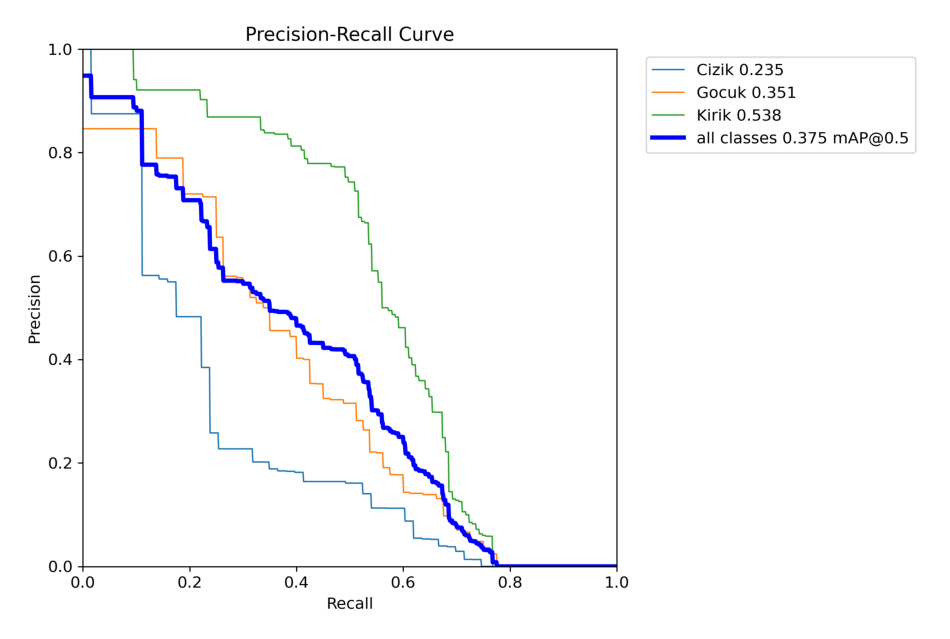

In [5]:
from PIL import Image
import matplotlib.pyplot as plt, os

p = '/content/drive/MyDrive/tez_arac_hasar/modeller/hasar_yolo11m-seg/MaskPR_curve.png'
plt.figure(figsize=(12, 9))
plt.imshow(Image.open(p))
plt.axis('off'); plt.show()